In [1]:
!pip -q install timm datasets onnx onnxruntime fastapi uvicorn python-multipart

import torch
print(torch.__version__, torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "GPU 없음! 런타임 유형을 T4로 바꾸세요")

2.11.0+cu130 True
Tesla T4


print(torch.__version__, torch.cuda.is_available())	: Asked PyTorch for its version and whether it can see a GPU	2.11.0+cu130 True

print(torch.cuda.get_device_name(0) ...) :	Printed the GPU’s name, or a warning if there isn’t one	Tesla T4

In [2]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
RUN_DIR = Path('/content/drive/MyDrive/visual-search')
RUN_DIR.mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


| Line | What it did |
|---|---|
| `drive.mount('/content/drive')` | Asked for your permission, then attached your Drive. The "Mounted" message is its only output. |
| `RUN_DIR = Path(...)` | Set the path where all your results will be saved. This only stores the path; it doesn't create anything yet. |
| `RUN_DIR.mkdir(parents=True, exist_ok=True)` | Created a `visual-search` folder in your Drive, or did nothing if it already existed. It prints nothing. |


In [3]:
from datasets import load_dataset

ds = load_dataset('ashraq/fashion-product-images-small', split='train')
print(ds)
print(ds[0])

README.md:   0%|          | 0.00/867 [00:00<?, ?B/s]

data/train-00000-of-00002-6cff4c59f91661(…): reconstructing file:   0%|          |  0.00B /  136MB            

data/train-00000-of-00002-6cff4c59f91661(…): downloading bytes:           |  0.00B            

data/train-00001-of-00002-bb459e5ac5f01e(…): reconstructing file:   0%|          |  0.00B /  135MB            

data/train-00001-of-00002-bb459e5ac5f01e(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/44072 [00:00<?, ? examples/s]

Dataset({
    features: ['id', 'gender', 'masterCategory', 'subCategory', 'articleType', 'baseColour', 'season', 'year', 'usage', 'productDisplayName', 'image'],
    num_rows: 44072
})
{'id': 15970, 'gender': 'Men', 'masterCategory': 'Apparel', 'subCategory': 'Topwear', 'articleType': 'Shirts', 'baseColour': 'Navy Blue', 'season': 'Fall', 'year': 2011.0, 'usage': 'Casual', 'productDisplayName': 'Turtle Check Men Navy Blue Shirt', 'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=60x80 at 0x7BE654746660>}



| Part | Meaning |
|---|---|
| `HF_TOKEN` warning | Harmless. You downloaded from Hugging Face without an account token, which only means slower speeds and lower rate limits. The data is public, so no action is needed. |
| `README.md`, `data/train-...` progress bars | The dataset downloaded as two files of about 136 MB and 135 MB. All the bars reached 100%. |
| `Generating train split: 44072/44072` | Hugging Face converted the files into a table of 44,072 rows. |
| `Dataset({... num_rows: 44072})` | This is `print(ds)`. It lists the 11 columns and the row count, matching the tutorial's "about 44,000 images". |
| `{'id': 15970, ...}` | This is `print(ds[0])`, the first product. It's a men's navy blue "Turtle Check" shirt. |

what we are using are image and articleType like t-shirts, watches, shoes etc..

total category num: 141
[('Tshirts', 7065), ('Shirts', 3212), ('Casual Shoes', 2845), ('Watches', 2542), ('Sports Shoes', 2016), ('Kurtas', 1844), ('Tops', 1762), ('Handbags', 1759), ('Heels', 1323), ('Sunglasses', 1073), ('Wallets', 928), ('Flip Flops', 914), ('Sandals', 895), ('Briefs', 847), ('Belts', 813), ('Backpacks', 724), ('Socks', 686), ('Formal Shoes', 637), ('Perfume and Body Mist', 603), ('Jeans', 602), ('Shorts', 547), ('Trousers', 530), ('Flats', 500), ('Bra', 477), ('Dresses', 464)]


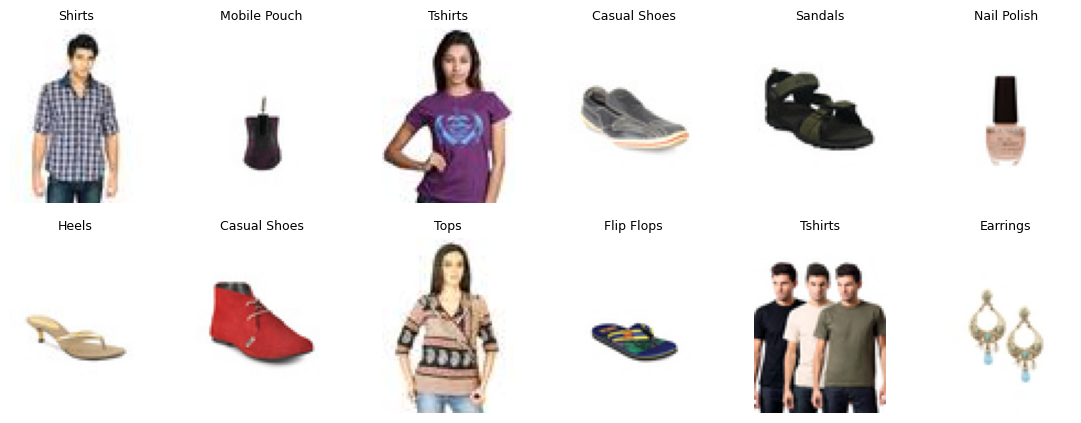

In [4]:
from collections import Counter
import matplotlib.pyplot as plt

labels = ds['articleType']
counts = Counter(labels)
print('total category num:', len(counts))
print(counts.most_common(25))

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, i in zip(axes.flat, range(0, 12000, 1000)):
    ax.imshow(ds[i]['image'])
    ax.set_title(ds[i]['articleType'], fontsize=9)
    ax.axis('off')
plt.show()


| Part | What it did |
|---|---|
| `labels = ds['articleType']` | Pulled out the category name of all 44,072 products as one list |
| `Counter(labels)` | Counted how many products each category has |
| `len(counts)` | The number of different categories, **141** |
| `counts.most_common(25)` | The 25 biggest categories, sorted from most to fewest |

range(0, 12000, 1000) picks rows 0, 1000, 2000 and so on up to 11000. That’s why you get a spread of categories rather than 12 shirts, since the dataset is ordered by product ID, not by type.

0번부터 12000번 직전까지 1,000개씩 건너뛰며 인덱스를 선택, 전체 데이터셋에서 0번째, 1000번째, 2000번째, 3000번째 ... 11000번째 위치에 있는 이미지를 정확하게 가져와서 차례대로 나열함.

In [5]:
import json, random
from collections import defaultdict

SEED = 42
TOP_K = 20
MAX_PER_CLASS = 1500   # reducing learning time so that max_class = 1500

class_names = sorted(c for c, _ in counts.most_common(TOP_K))
class_to_id = {c: k for k, c in enumerate(class_names)}

by_class = defaultdict(list)
for i, lab in enumerate(labels):
    if lab in class_to_id:
        by_class[lab].append(i)

rng = random.Random(SEED)
splits = {'train': [], 'val': [], 'test': []}
for lab, idxs in by_class.items():
    rng.shuffle(idxs)
    idxs = idxs[:MAX_PER_CLASS]
    n_val = n_test = max(1, int(len(idxs) * 0.1))
    y = class_to_id[lab]
    splits['test']  += [(i, y) for i in idxs[:n_test]]
    splits['val']   += [(i, y) for i in idxs[n_test:n_test + n_val]]
    splits['train'] += [(i, y) for i in idxs[n_test + n_val:]]

(RUN_DIR / 'splits.json').write_text(json.dumps({'class_names': class_names, **splits}))
print({k: len(v) for k, v in splits.items()})

{'train': 17647, 'val': 2199, 'test': 2199}


모델 학습을 위해 전체 데이터셋에서 가장 많이 등장하는 상위 20개 카테고리를 선택한 뒤, 학습용(train), 검증용(val), 테스트용(test) 데이터셋으로 분할(Split)하는 과정


| Step | What it did |
|---|---|
| Top 20 | Kept only the 20 largest categories and dropped the other 121 |
| Shuffle | Mixed each category's photos randomly. `SEED = 42` makes the shuffle repeatable, so you get the same split every run. |
| Cap at 1,500 | Tshirts has 7,065 photos but only 1,500 are kept, so one category doesn't dominate. This is also why the total is 22,045 and not about 33,000. |
| 10% / 10% / rest | Within each category, 10% goes to test, 10% to validation and the rest to training |


In [6]:
from PIL import Image
from torchvision import transforms as T

MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
IMG_SIZE = 224

class PadToSquare:
# make the photo square
    def __call__(self, img):
        w, h = img.size
        s = max(w, h)
        canvas = Image.new('RGB', (s, s), (255, 255, 255))
        canvas.paste(img, ((s - w) // 2, (s - h) // 2))
        return canvas

train_tf = T.Compose([
    PadToSquare(),
    T.RandomResizedCrop(IMG_SIZE, scale=(0.75, 1.0), ratio=(0.9, 1.1)),
    T.RandomHorizontalFlip(),
    T.ColorJitter(0.2, 0.2, 0.2),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])
eval_tf = T.Compose([PadToSquare(), T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor(), T.Normalize(MEAN, STD)])

MEAN, STD: PyTorch의 사전 학습된(Pre-trained) 이미지 분석 모델들이 보편적으로 사용하는 RGB 채널별 평균과 표준편차 값입니다. 이미지의 픽셀 값을 정규화(Normalize)
IMG_SIZE = 224: 학습할 이미지의 해상도(가로, 세로 크기)를 224픽셀로 설정
PadToSquare는 가로와 세로 중 더 긴 쪽을 기준으로 하얀색(255, 255, 255) 배경의 정사각형 캔버스를 만들고, 그 중앙에 원본 이미지를 얹어서 비율 왜곡 없이 이미지를 정사각형으로 만듬

In [7]:
from torch.utils.data import Dataset, DataLoader

class ProductImages(Dataset):
    def __init__(self, items, transform):
        self.items, self.transform = items, transform
    def __len__(self):
        return len(self.items)
    def __getitem__(self, k):
        idx, y = self.items[k]
        img = ds[int(idx)]['image'].convert('RGB')
        return self.transform(img), y, idx

BATCH = 64
train_loader = DataLoader(ProductImages(splits['train'], train_tf), batch_size=BATCH, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(ProductImages(splits['val'],   eval_tf),  batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(ProductImages(splits['test'],  eval_tf),  batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)

x, y, _ = next(iter(train_loader))
print(x.shape, y[:10])

torch.Size([64, 3, 224, 224]) tensor([ 6, 15,  1,  3, 16,  4,  7,  9,  6,  7])


PyTorch에서 학습에 필요한 데이터를 효율적으로 공급하기 위해 커스텀 데이터셋(Dataset)을 만들고, 이를 배치(Batch) 단위로 쪼개서 로드해주는 데이터로더(DataLoader)를 설정



| Number | Meaning |
|---|---|
| 64 | Batch size, set by `BATCH = 64`. The model sees 64 photos at once. |
| 3 | Colour channels: red, green, blue |
| 224 | Image height |
| 224 | Image width |



In [8]:
import timm
import torch.nn as nn
import torch.nn.functional as F

class ProductModel(nn.Module):
    def __init__(self, num_classes, backbone='resnet50', pretrained=True):
        super().__init__()
        # num_classes=0 → 마지막 분류층을 떼고 2048차원 특징 벡터만 내보내는 몸통
        self.backbone = timm.create_model(backbone, pretrained=pretrained, num_classes=0)
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(self.backbone.num_features, num_classes))

    def forward(self, x):
        return self.head(self.backbone(x))

    def embed(self, x):
        # Step 6에서 유사 상품 검색에 쓸 임베딩 (길이 1로 정규화)
        return F.normalize(self.backbone(x), dim=-1)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = ProductModel(len(class_names)).to(device)

logits = model(x[:4].to(device))
print(logits.shape)   # torch.Size([4, 20])
print(sum(p.numel() for p in model.parameters()) / 1e6, 'M parameters')

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

torch.Size([4, 20])
23.549012 M parameters


이미지 분석 모델인 ResNet50을 불러와서, 우리 데이터셋에 맞게 가공하고 유사도 검색(Embedding) 기능까지 추가한 커스텀 딥러닝 모델 클래스를 정의하고 테스트

In [9]:
import math, time, csv

EPOCHS, WARMUP_EPOCHS, FREEZE_EPOCHS, PATIENCE = 10, 1, 1, 3
LR, WEIGHT_DECAY = 3e-4, 0.05

torch.manual_seed(SEED)
model = ProductModel(len(class_names)).to(device)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

steps_per_epoch = len(train_loader)
total_steps, warmup_steps = EPOCHS * steps_per_epoch, WARMUP_EPOCHS * steps_per_epoch

def lr_lambda(step):
    if step < warmup_steps:                       # warmup: 0에서 LR까지 천천히 올림
        return (step + 1) / warmup_steps
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * (1 + math.cos(math.pi * min(1.0, progress)))   # cosine: 부드럽게 0까지 내림

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
scaler = torch.amp.GradScaler('cuda')

In [10]:
def run_epoch(loader, train):
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    for x, y, _ in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.set_grad_enabled(train), torch.autocast('cuda', dtype=torch.float16):
            logits = model(x)
            loss = criterion(logits, y)
        if train:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
        total_loss += loss.item() * len(y)
        correct += (logits.argmax(1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n

In [11]:
log_path = RUN_DIR / 'metrics.csv'
with open(log_path, 'w', newline='') as f:
    csv.writer(f).writerow(['epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc', 'lr'])

best_acc, bad = -1.0, 0
for epoch in range(1, EPOCHS + 1):
    # 첫 epoch는 머리(head)만 학습, 그 다음부터 몸통까지 전부
    for p in model.backbone.parameters():
        p.requires_grad = epoch > FREEZE_EPOCHS

    t0 = time.time()
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader, train=False)
    lr = optimizer.param_groups[0]['lr']
    print(f'epoch {epoch:2d} | train {tr_loss:.3f}/{tr_acc:.3f} | val {va_loss:.3f}/{va_acc:.3f} | lr {lr:.1e} | {time.time()-t0:.0f}s')
    with open(log_path, 'a', newline='') as f:
        csv.writer(f).writerow([epoch, tr_loss, tr_acc, va_loss, va_acc, lr])

    if va_acc > best_acc:
        best_acc, bad = va_acc, 0
        torch.save({'state_dict': model.state_dict(), 'class_names': class_names}, RUN_DIR / 'best.pt')
    else:
        bad += 1
        if bad >= PATIENCE:
            print('early stop'); break

print('best val acc:', best_acc)

epoch  1 | train 2.813/0.221 | val 2.498/0.461 | lr 3.0e-04 | 94s
epoch  2 | train 1.063/0.835 | val 0.823/0.910 | lr 2.9e-04 | 108s
epoch  3 | train 0.783/0.926 | val 0.770/0.925 | lr 2.6e-04 | 110s
epoch  4 | train 0.744/0.943 | val 0.752/0.933 | lr 2.2e-04 | 108s
epoch  5 | train 0.720/0.950 | val 0.743/0.939 | lr 1.8e-04 | 110s
epoch  6 | train 0.700/0.959 | val 0.739/0.940 | lr 1.2e-04 | 107s
epoch  7 | train 0.682/0.966 | val 0.725/0.948 | lr 7.5e-05 | 108s
epoch  8 | train 0.670/0.973 | val 0.727/0.948 | lr 3.5e-05 | 109s
epoch  9 | train 0.662/0.977 | val 0.729/0.948 | lr 9.0e-06 | 108s
epoch 10 | train 0.660/0.977 | val 0.728/0.950 | lr 0.0e+00 | 108s
best val acc: 0.9504320145520692




| Epochs | What you see | Why |
|---|---|---|
| 1 | Train accuracy only 0.221, validation 0.461 | `FREEZE_EPOCHS = 1` froze the ResNet body, so only the new head learned. Validation is higher because training is averaged while the model improves, and it also has augmentation and dropout. This is the low first epoch I warned about. |
| 2 | Jumps to 0.835 / 0.910 | The body unfroze, so the whole model now learns. This is the biggest gain. |
| 3–7 | Slow, steady improvement | The model refines details. Loss keeps falling and validation accuracy rises to 0.948. |
| 8–10 | Nearly flat | The learning rate is almost 0, so the weights barely change. |


로그 파일 초기화 (metrics.csv):

RUN_DIR / 'metrics.csv' 경로에 파일을 열고, 에폭(epoch)별 손실(loss), 정확도(accuracy), 학습률(learning rate)을 기록할 헤더를 작성합니다.

점진적 미세조정 (Gradual Fine-tuning / Freezing):

epoch > FREEZE_EPOCHS (여기서 FREEZE_EPOCHS = 1):
첫 번째 에폭에서는 이미지 특징을 추출하는 몸통(model.backbone)의 파라미터를 고정(requires_grad = False)하고, 우리가 새로 붙인 분류기 머리(model.head)만 학습시킵니다.
두 번째 에폭부터는 몸통의 잠금을 해제(requires_grad = True)하여 이미지 추출기부터 분류기까지 모델 전체를 정교하게 미세조정(Fine-tuning)합니다. 이는 사전 학습된 지식을 망가뜨리지 않으면서 안정적으로 학습시키는 훌륭한 전략입니다.

에폭 실행 및 기록 (run_epoch):

run_epoch(..., train=True)로 훈련 데이터를 학습시키고, run_epoch(..., train=False)로 검증 데이터에 대한 성능을 평가합니다.
매 에폭이 끝날 때마다 결과(손실율, 정확도, 현재 학습률, 소요 시간)를 화면에 출력하고 metrics.csv에 누적 저장합니다.

모델 저장 (Checkpointing) 및 조기 종료 (Early Stopping):

검증 정확도(va_acc)가 기존 최고치(best_acc)보다 높으면 모델의 가중치(state_dict)와 클래스 이름을 best.pt 파일로 저장하고, 인내심 카운터(bad)를 0으로 초기화합니다.
정확도가 개선되지 않으면 bad 카운터를 1 증가시킵니다. 이 수치가 설정한 기준(PATIENCE = 3)에 도달하면 과적합(Overfitting)을 방지하기 위해 학습을 중간에 중단(early stop)합니다.


In [12]:
import numpy as np

ckpt = torch.load(RUN_DIR / 'best.pt', map_location=device)
model.load_state_dict(ckpt['state_dict'])
model.eval()

all_pred, all_true = [], []
with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
    for x, y, _ in test_loader:
        all_pred.append(model(x.to(device)).argmax(1).cpu())
        all_true.append(y)
y_pred = torch.cat(all_pred).numpy()
y_true = torch.cat(all_true).numpy()
print('test accuracy:', (y_pred == y_true).mean())

test accuracy: 0.9554342883128695


test accuracy: 0.9554342883128695

학습이 끝난 후, 저장된 가장 성능이 좋은 모델 가중치를 불러와서 한 번도 보지 못한 테스트 데이터셋(Test Dataset)으로 모델의 최종 성능(정확도)을 측정하는 평가 코드

                       precision    recall  f1-score   support

            Backpacks      0.986     0.972     0.979        72
                Belts      1.000     1.000     1.000        81
               Briefs      0.988     0.988     0.988        84
         Casual Shoes      0.880     0.880     0.880       150
           Flip Flops      0.933     0.912     0.922        91
         Formal Shoes      0.925     0.984     0.954        63
             Handbags      0.980     0.967     0.973       150
                Heels      0.956     0.977     0.966       132
                Jeans      1.000     1.000     1.000        60
               Kurtas      0.937     0.987     0.961       150
Perfume and Body Mist      0.984     1.000     0.992        60
              Sandals      0.920     0.910     0.915        89
               Shirts      0.973     0.953     0.963       150
                Socks      1.000     1.000     1.000        68
         Sports Shoes      0.917     0.887     0.902  

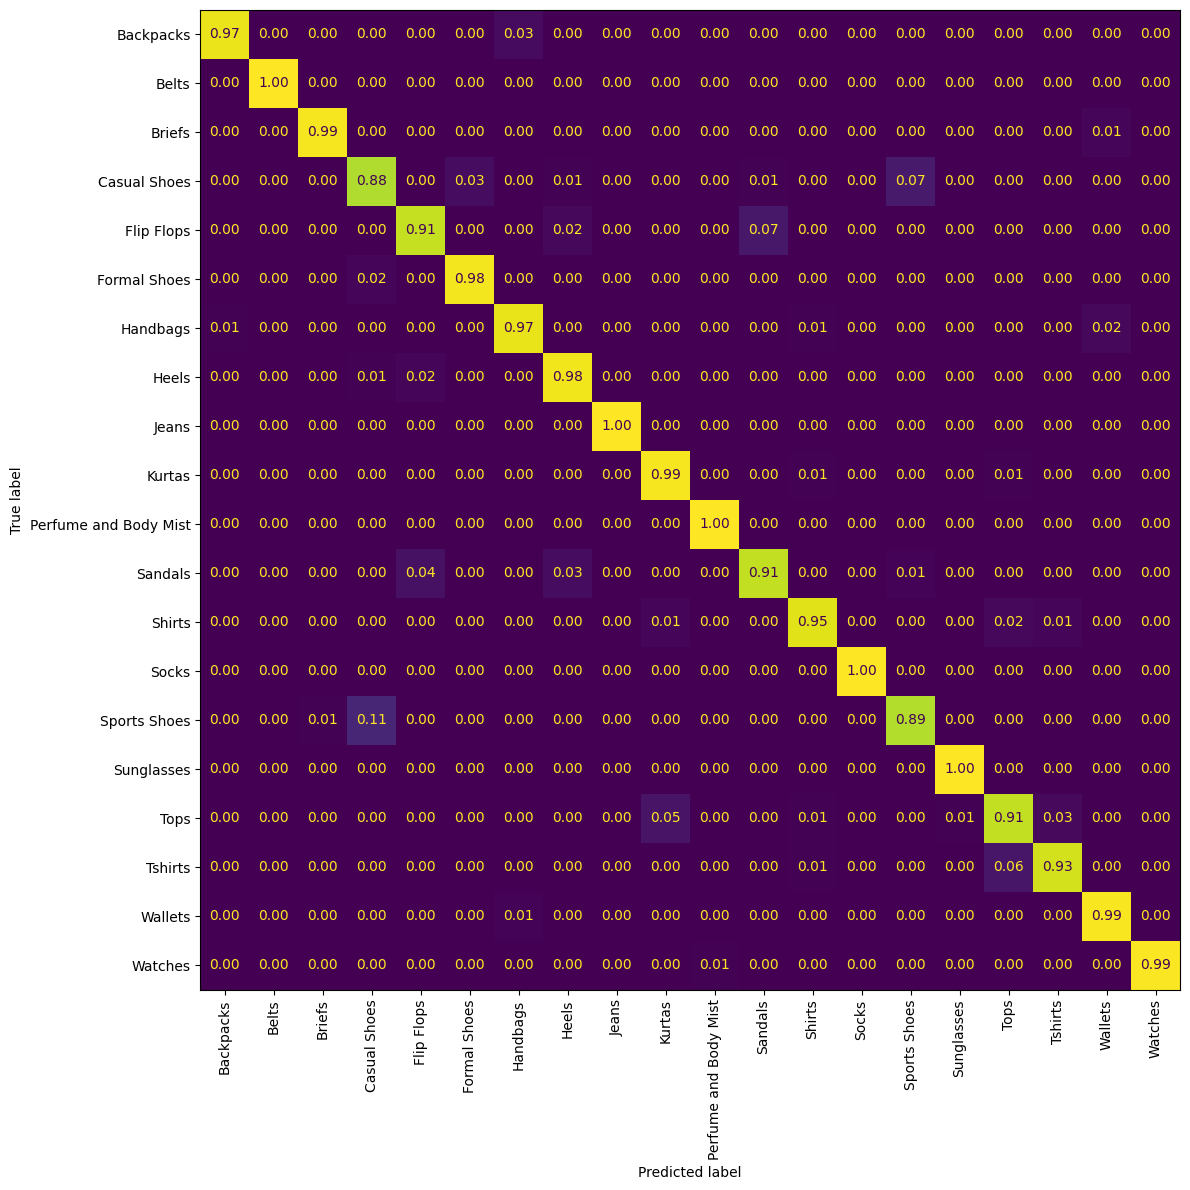

In [13]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

cm = confusion_matrix(y_true, y_pred, normalize='true')
fig, ax = plt.subplots(figsize=(12, 12))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, xticks_rotation=90, values_format='.2f', colorbar=False)
plt.tight_layout()
plt.savefig(RUN_DIR / 'confusion_matrix.png', dpi=120)
plt.show()

분류 보고서 출력 (classification_report):

각 카테고리(클래스)별로 정밀도(Precision), 재현율(Recall), F1-점수(F1-score) 및 해당 카테고리의 실제 데이터 개수(Support)를 계산하여 표 형태로 출력합니다.
출력 결과를 보면 Belts, Jeans, Socks, Watches 등은 99%~100%에 달하는 완벽한 성능을 보여주며, 가장 낮은 Casual Shoes도 88% 수준으로 전반적인 분류 성능이 매우 우수함을 정량적으로 확인할 수 있습니다.


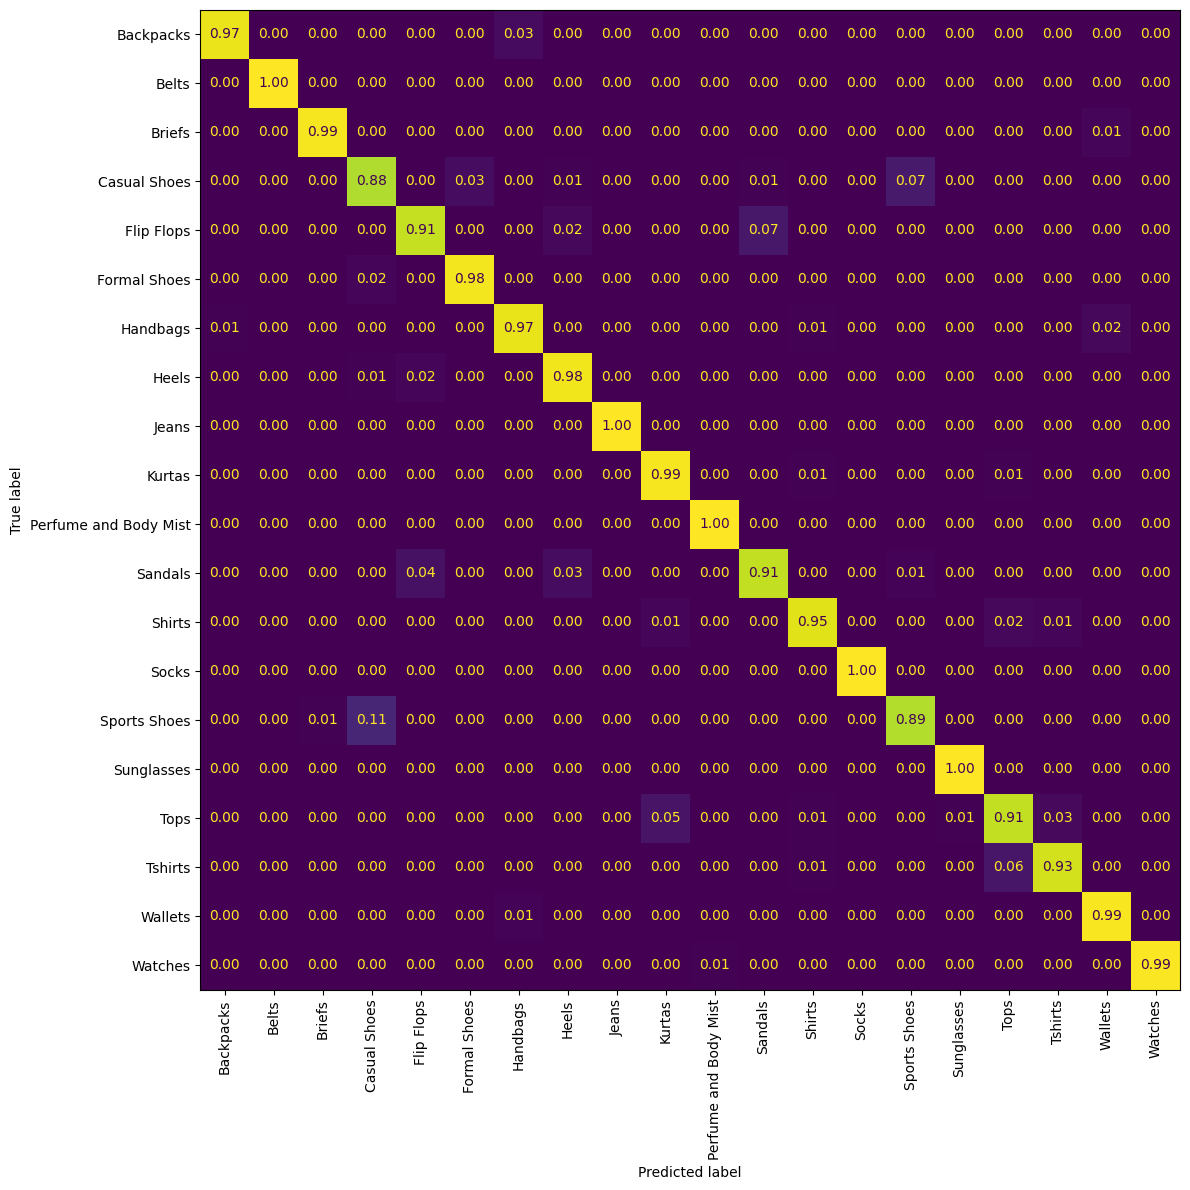혼동 행렬 시각화 (confusion_matrix & ConfusionMatrixDisplay):

confusion_matrix(..., normalize='true'): 어떤 카테고리를 다른 카테고리로 잘못 예측했는지 비율(0.0 ~ 1.0)로 변환해 행렬 형태로 계산합니다.
ConfusionMatrixDisplay(...).plot(...): 이 행렬을 가로세로 12인치 크기의 히트맵(Heatmap) 그래프로 그립니다. 대각선(왼쪽 위에서 오른쪽 아래) 영역이 1.0(노란색)에 가까울수록 정답을 아주 잘 맞췄다는 뜻입니다.
예를 들어, 그래프상에서 Sports Shoes 행의 Casual Shoes 열 교차점에 0.11이 적혀 있는데, 이는 모델이 '스포츠화'의 11%를 '캐주얼화'로 헷갈려했다는 구체적인 오답 분석을 시각적으로 보여줍니다.

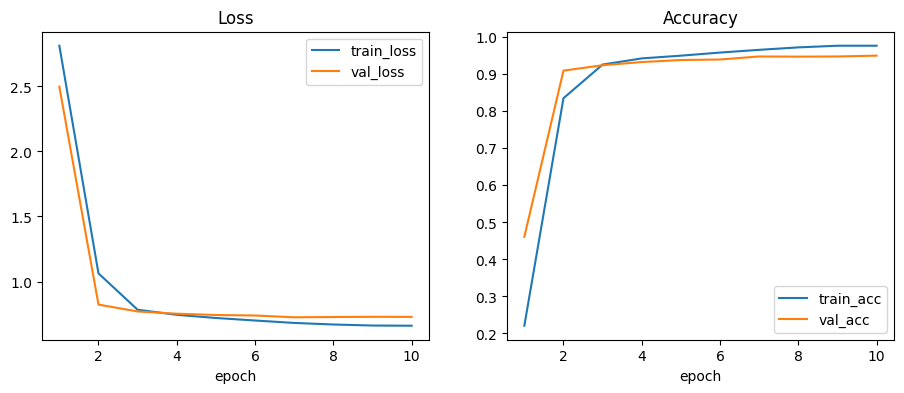

In [14]:
import pandas as pd

m = pd.read_csv(RUN_DIR / 'metrics.csv')
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
m.plot(x='epoch', y=['train_loss', 'val_loss'], ax=a1, title='Loss')
m.plot(x='epoch', y=['train_acc', 'val_acc'], ax=a2, title='Accuracy')
plt.savefig(RUN_DIR / 'curves.png', dpi=120)
plt.show()

손실(Loss) 그래프: 에폭이 진행됨에 따라 train_loss와 val_loss가 함께 완만하게 하강하는 모습을 보여야 학습이 잘 된 것입니다. 만약 train_loss는 계속 떨어지는데 val_loss가 다시 상승하기 시작한다면 과적합(Overfitting)이 발생했다는 신호입니다.


정확도(Accuracy) 그래프: 에폭이 진행될수록 train_acc와 val_acc가 완만하게 상승하여 높은 구간에서 평탄해지는(수렴하는) 모습을 보입니다.



| Question | Answer from the plots |
|---|---|
| Did it learn? | Yes. Loss falls and accuracy rises. |
| Overfitting? | Only a little. The gap at the end is about 3 points, and validation loss never turns upward. |
| Trained long enough? | Yes. The lines flatten, so more epochs would add little. |
| Why the flat ending? | The learning rate fell to zero, so the weights stopped changing. |


In [15]:
import numpy as np

def extract_embeddings(loader):
    model.eval()
    embs, ys, idxs = [], [], []
    with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
        for x, y, idx in loader:
            embs.append(model.embed(x.to(device)).float().cpu())
            ys.append(y); idxs.append(idx)
    return torch.cat(embs), torch.cat(ys), torch.cat(idxs)

# 갤러리는 증강 없이 추출해야 해서 eval_tf로 새 loader를 만든다
gallery_loader = DataLoader(ProductImages(splits['train'], eval_tf), batch_size=128, shuffle=False, num_workers=2)
g_emb, g_y, g_idx = extract_embeddings(gallery_loader)
q_emb, q_y, q_idx = extract_embeddings(test_loader)
print(g_emb.shape, q_emb.shape)
np.savez(RUN_DIR / 'gallery.npz', emb=g_emb.numpy(), y=g_y.numpy(), idx=g_idx.numpy())

torch.Size([17647, 2048]) torch.Size([2199, 2048])


유사 상품 검색(Visual Search) 시스템의 핵심 단계인 이미지 임베딩(Feature Embedding) 추출 및 저장



| Piece | What it did |
|---|---|
| `model.embed(x)` | Ran each photo through the ResNet body only, skipping the 20-way head. That gives the 2,048 numbers from before the classification step. |
| `F.normalize` (inside `embed`) | Scaled every vector to length 1, which Step 6's similarity calculation depends on |
| `eval_tf` for the gallery | Used the plain, non-augmented transform, so each training photo gets one stable vector. The code builds a new loader because the training loader has random augmentation. |
| `torch.save` / `np.savez` | Saved the gallery to your Drive so the API in Step 7 can use it. It prints nothing. |



In [16]:
sims = q_emb @ g_emb.T            # 둘 다 길이 1이라 내적 = 코사인 유사도
topk = sims.topk(10, dim=1).indices
hit = (g_y[topk] == q_y[:, None])   # [쿼리 수, 10], 같은 카테고리면 True

for k in (1, 5, 10):
    recall = hit[:, :k].any(dim=1).float().mean().item()
    precision = hit[:, :k].float().mean().item()
    print(f'Recall@{k}: {recall:.3f}   Precision@{k}: {precision:.3f}')

Recall@1: 0.949   Precision@1: 0.949
Recall@5: 0.973   Precision@5: 0.950
Recall@10: 0.980   Precision@10: 0.950


추출된 이미지 임베딩들을 비교하여 유사 상품 검색(Visual Search) 성능을 정량적으로 평가(Evaluation)

sims.topk(10, dim=1): 각 쿼리 이미지에 대해 유사도가 가장 높은 상위 10개의 갤러리 이미지 인덱스를 뽑아냅니다.

g_y[topk] == q_y[:, None]: 찾아낸 상위 10개 상품의 실제 카테고리(g_y[topk])와 쿼리 이미지의 실제 카테고리(q_y)를 비교합니다.

두 카테고리가 일치하면 True, 다르면 False가 채워진 [쿼리 개수, 10] 크기의 불리언(Boolean) 행렬 hit가 만들어집니다.



| K | Recall@K | Precision@K | Meaning |
|---|---|---|---|
| 1 | 0.949 | 0.949 | The single closest photo is the right category 94.9% of the time |
| 5 | 0.973 | 0.950 | In 97.3% of searches, at least one of the top 5 matches |
| 10 | 0.980 | 0.950 | Same, with 10 results |



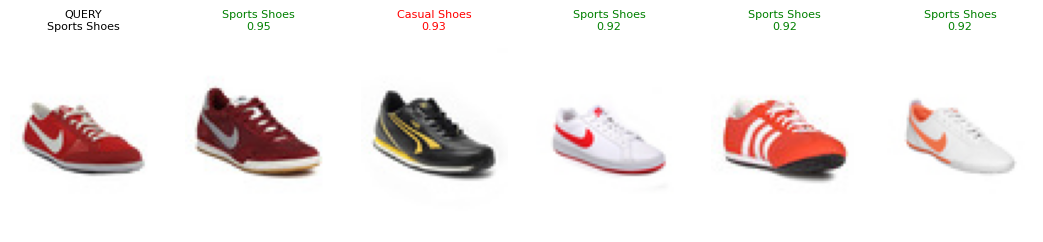

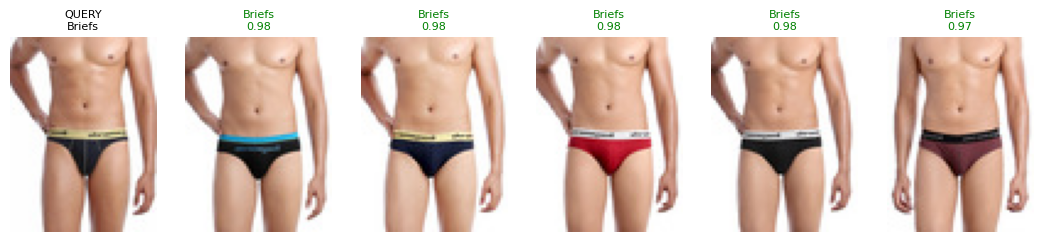

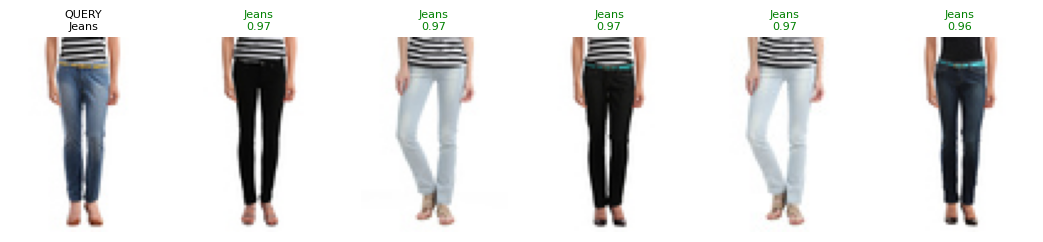

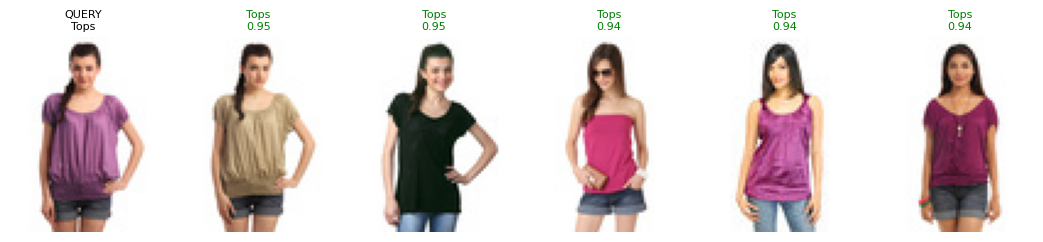

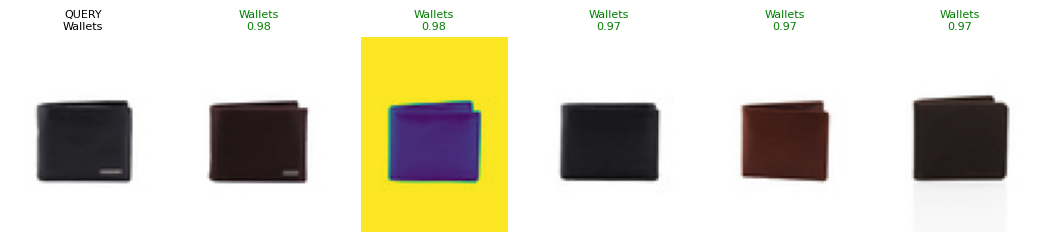

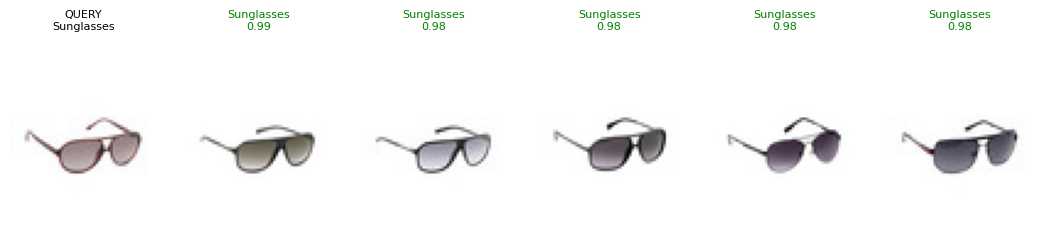

In [17]:
def show_similar(qi, k=5):
    fig, axes = plt.subplots(1, k + 1, figsize=(2.2 * (k + 1), 2.6))
    axes[0].imshow(ds[int(q_idx[qi])]['image']); axes[0].set_title('QUERY\n' + class_names[q_y[qi]], fontsize=8)
    for j, gi in enumerate(topk[qi, :k]):
        ok = g_y[gi] == q_y[qi]
        axes[j + 1].imshow(ds[int(g_idx[gi])]['image'])
        axes[j + 1].set_title(f'{class_names[g_y[gi]]}\n{sims[qi, gi]:.2f}', fontsize=8, color='green' if ok else 'red')
    for a in axes: a.axis('off')
    plt.show()

for qi in random.Random(0).sample(range(len(q_y)), 6):
    show_similar(qi)

유사도를 기반으로 쿼리 이미지와 가장 유사한 상위 5개의 추천 상품들을 화면에 나란히 시각화하여 보여주는 코드

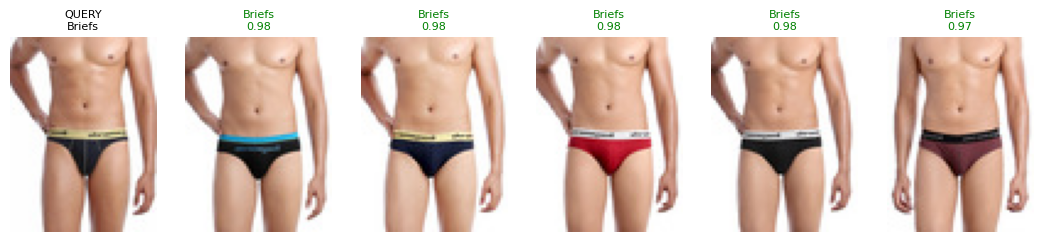

시각화 결과에서 '실패 케이스(Failure Cases)'로 분류

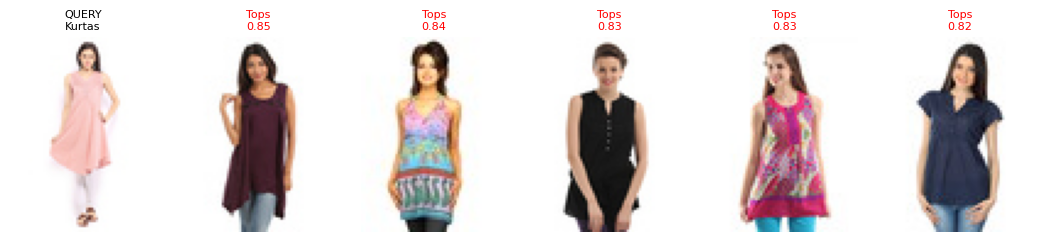



| Rank | Label | Score | What it looks like |
|---|---|---|---|
| 1 | Shirts (wrong) | 0.88 | A man in a **pink button-up shirt** |
| 2 | Tshirts | 0.85 | A cream polo |
| 3 | Tshirts | 0.85 | A teal polo |
| 4 | Tshirts | 0.84 | A navy sleeveless top |
| 5 | Shirts (wrong) | 0.84 | A man in a **blue button-up shirt** |


In [5]:
!pip -q install timm onnx onnxruntime

import json, torch, timm
import torch.nn as nn
import torch.nn.functional as F
from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')
RUN_DIR = Path('/content/drive/MyDrive/visual-search')
IMG_SIZE = 224
class_names = json.loads((RUN_DIR / 'splits.json').read_text())['class_names']

class ProductModel(nn.Module):
    def __init__(self, num_classes, backbone='resnet50', pretrained=True):
        super().__init__()
        self.backbone = timm.create_model(backbone, pretrained=pretrained, num_classes=0)
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(self.backbone.num_features, num_classes))
    def forward(self, x):
        return self.head(self.backbone(x))
    def embed(self, x):
        return F.normalize(self.backbone(x), dim=-1)

print(RUN_DIR, RUN_DIR.is_dir(), len(class_names), 'classes')
!ls -lh "{RUN_DIR}"

Mounted at /content/drive
/content/drive/MyDrive/visual-search True 20 classes
total 319M
-rw------- 1 root root  91M Nov  5 07:36 best.pt
-rw------- 1 root root 154K Nov  5 07:50 confusion_matrix.png
-rw------- 1 root root  44K Nov  5 07:58 curves.png
-rw------- 1 root root 139M Nov  5 08:32 gallery.npz
-rw------- 1 root root 1014 Nov  5 07:36 metrics.csv
-rw------- 1 root root  90M Nov  5 09:05 model.onnx
-rw------- 1 root root 265K Nov  5 07:00 splits.json


In [6]:
class ExportWrapper(nn.Module):
    def __init__(self, m):
        super().__init__(); self.m = m
    def forward(self, x):
        feats = self.m.backbone(x)
        return self.m.head(feats), F.normalize(feats, dim=-1)

model_cpu = ProductModel(len(class_names), pretrained=False)
model_cpu.load_state_dict(torch.load(RUN_DIR / 'best.pt', map_location='cpu')['state_dict'])
wrapper = ExportWrapper(model_cpu).eval()

dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
torch.onnx.export(wrapper, dummy, str(RUN_DIR / 'model.onnx'),
                  input_names=['image'], output_names=['logits', 'embedding'],
                  dynamic_axes={'image': {0: 'batch'}, 'logits': {0: 'batch'}, 'embedding': {0: 'batch'}},
                  opset_version=17, dynamo=False)

/tmp/ipykernel_1488/3824368338.py:13: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(wrapper, dummy, str(RUN_DIR / 'model.onnx'),



| Line | What it did |
|---|---|
| `ProductModel(..., pretrained=False)` | Built an empty copy of the model. It skips the ImageNet download because the real weights come next. |
| `load_state_dict(torch.load('best.pt'))` | Loaded your best trained weights into that copy. This is the epoch-10 model. |
| `ExportWrapper` | Made the model return two things at once: the 20 class scores and the normalised 2,048-number embedding |
| `dummy = torch.randn(1, 3, 224, 224)` | A random fake image. The exporter runs it through the model once to record the steps. |
| `torch.onnx.export(...)` | Wrote the whole model, weights included, to `model.onnx` in your Drive |



In [7]:
import time
import numpy as np
import onnxruntime as ort

sess = ort.InferenceSession(str(RUN_DIR / 'model.onnx'), providers=['CPUExecutionProvider'])
x1 = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
with torch.no_grad():
    pt_logits, _ = wrapper(x1)
onnx_logits, _ = sess.run(None, {'image': x1.numpy()})
print('max diff:', np.abs(pt_logits.numpy() - onnx_logits).max())   # 1e-4 이하면 OK

t0 = time.time()
for _ in range(20):
    sess.run(None, {'image': x1.numpy()})
print(f'CPU latency: {(time.time() - t0) / 20 * 1000:.1f} ms / image')

max diff: 3.0994415e-06
CPU latency: 84.2 ms / image


In [8]:
%%writefile app.py
import io, json
import numpy as np
import onnxruntime as ort
from fastapi import FastAPI, File, UploadFile
from PIL import Image

RUN_DIR = '/content/drive/MyDrive/visual-search'
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

sess = ort.InferenceSession(f'{RUN_DIR}/model.onnx', providers=['CPUExecutionProvider'])
class_names = json.load(open(f'{RUN_DIR}/splits.json'))['class_names']
gallery = np.load(f'{RUN_DIR}/gallery.npz')
g_emb, g_y, g_idx = gallery['emb'], gallery['y'], gallery['idx']

app = FastAPI(title='Marketplace Visual Search')

def preprocess(data: bytes):
    img = Image.open(io.BytesIO(data)).convert('RGB')
    s = max(img.size)
    canvas = Image.new('RGB', (s, s), (255, 255, 255))
    canvas.paste(img, ((s - img.width) // 2, (s - img.height) // 2))
    arr = np.asarray(canvas.resize((224, 224), Image.BILINEAR), dtype=np.float32) / 255.0
    arr = (arr - MEAN) / STD
    return arr.transpose(2, 0, 1)[None]          # HWC -> 1xCxHxW

def run(data: bytes):
    logits, emb = sess.run(None, {'image': preprocess(data)})
    return logits[0], emb[0]

@app.post('/predict')
async def predict(file: UploadFile = File(...), top_k: int = 3):
    logits, _ = run(await file.read())
    probs = np.exp(logits - logits.max()); probs /= probs.sum()
    best = probs.argsort()[::-1][:top_k]
    return {'predictions': [{'label': class_names[i], 'prob': round(float(probs[i]), 4)} for i in best]}

@app.post('/similar')
async def similar(file: UploadFile = File(...), k: int = 5):
    _, emb = run(await file.read())
    sims = g_emb @ emb
    best = sims.argsort()[::-1][:k]
    return {'results': [{'dataset_index': int(g_idx[i]), 'label': class_names[g_y[i]], 'score': round(float(sims[i]), 4)} for i in best]}

Writing app.py


In [10]:
import json
from datasets import load_dataset

ds = load_dataset('ashraq/fashion-product-images-small', split='train')
test_items = json.loads((RUN_DIR / 'splits.json').read_text())['test']
q_idx = [i for i, _ in test_items]
print(len(ds), len(q_idx), ds[int(q_idx[0])]['articleType'])

README.md:   0%|          | 0.00/867 [00:00<?, ?B/s]

data/train-00000-of-00002-6cff4c59f91661(…): reconstructing file:   0%|          |  0.00B /  136MB            

data/train-00000-of-00002-6cff4c59f91661(…): downloading bytes:           |  0.00B            

data/train-00001-of-00002-bb459e5ac5f01e(…): reconstructing file:   0%|          |  0.00B /  135MB            

data/train-00001-of-00002-bb459e5ac5f01e(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/44072 [00:00<?, ? examples/s]

44072 2199 Shirts


In [11]:
import importlib, io, app
importlib.reload(app)
from fastapi.testclient import TestClient

client = TestClient(app.app)
buf = io.BytesIO()
ds[int(q_idx[0])]['image'].save(buf, format='JPEG')

print(client.post('/predict', files={'file': ('q.jpg', buf.getvalue(), 'image/jpeg')}).json())
print(client.post('/similar', files={'file': ('q.jpg', buf.getvalue(), 'image/jpeg')}).json())

{'predictions': [{'label': 'Shirts', 'prob': 0.9086}, {'label': 'Formal Shoes', 'prob': 0.0061}, {'label': 'Jeans', 'prob': 0.0057}]}
{'results': [{'dataset_index': 9164, 'label': 'Shirts', 'score': 0.9608}, {'dataset_index': 25552, 'label': 'Shirts', 'score': 0.9604}, {'dataset_index': 35121, 'label': 'Shirts', 'score': 0.9581}, {'dataset_index': 10320, 'label': 'Shirts', 'score': 0.9574}, {'dataset_index': 997, 'label': 'Shirts', 'score': 0.9571}]}


**What the output shows**

| Line | Meaning |
|---|---|
| `44072 2199 Shirts` | The dataset has 44,072 rows and the test set has 2,199 images. The first test image's true category is **Shirts**. |
| `/predict` | The classifier is 90.9% sure it's Shirts. The next two guesses are 0.6% each. |
| `/similar` | The 5 most similar gallery items are all Shirts, with cosine scores 0.957–0.961. |

**Why it came out this way**

- **`/predict`:** the API pads the image to a square, resizes it to 224 with `BILINEAR`, normalises it, and runs the ONNX model. The 20 scores go through softmax. 0.909 for the right class is a confident answer, and the 2nd and 3rd entries are noise. "Formal Shoes" and "Jeans" at about 0.6% each are what's left over from label smoothing (0.1), which stops the model from ever reaching 100%. The confusion matrix said Shirts is mostly mistaken for Tshirts and Kurtas, and the small probabilities here are just spread thinly.
- **`/similar`:** the same image goes through the same model, and the 2,048-number embedding (length 1) is multiplied with all 17,647 stored gallery embeddings. A score of 0.96 means the vectors point in almost the same direction. All 5 hits are Shirts, so this query is a clean hit. Your Recall@5 of 0.973 means about 97 of 100 queries get at least one correct item in the top 5, and this is one of those.
- **`dataset_index`:** this is the row number in the Hugging Face dataset, so you can look up the image with `ds[9164]['image']`. The gallery stores indexes and not images, which is why `gallery.npz` is only 139M.

